In [3]:
# imports
import os
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
dataset_path = "./datasets/Cifar10/cifar10/"

train_data_path = os.path.join(dataset_path , "train")
test_data_path = os.path.join(dataset_path , "test")

In [5]:
# create data loaders
train_data_loader = tf.keras.utils.image_dataset_from_directory(
    train_data_path,
    image_size=(32, 32),
    batch_size=32,
    validation_split=0.2,
    subset="training",
    seed=42
)

validation_data_loader = tf.keras.utils.image_dataset_from_directory(
    train_data_path,
    image_size=(32, 32),
    batch_size=32,
    validation_split=0.2,
    subset="validation",
    seed=42
)

test_data = tf.keras.utils.image_dataset_from_directory(
    test_data_path,
    image_size=(32,32), 
    batch_size=32
)

Found 50000 files belonging to 10 classes.
Using 40000 files for training.
Found 50000 files belonging to 10 classes.
Using 10000 files for validation.
Found 10000 files belonging to 10 classes.


In [6]:
print("Classes:", train_data_loader.class_names)

for images, labels in train_data_loader.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Image shape: (32, 32, 32, 3)
Label shape: (32,)


In [12]:
def visualize_samples():
    plt.figure(figsize=(10, 6))

    for images, labels in train_data_loader.take(1):
        for i in range(10):
            plt.subplot(2, 5, i + 1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title(train_data_loader.class_names[labels[i]])
            plt.axis("off")
    
    plt.tight_layout()
    plt.show()

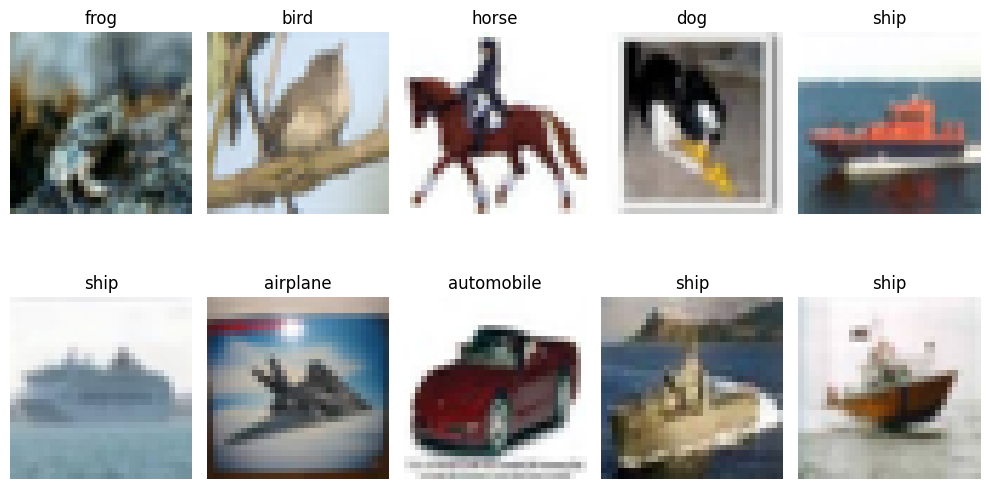

In [13]:
visualize_samples()

In [14]:
for images, labels in train_data_loader.take(1):
    image = images[0]

    print("Image shape:", image.shape)
    print("Minimum pixel value:", image.numpy().min())
    print("Maximum pixel value:", image.numpy().max())
    print("Label:", labels[0].numpy())
    print("Class:", train_data_loader.class_names[labels[0]])

Image shape: (32, 32, 3)
Minimum pixel value: 6.0
Maximum pixel value: 199.0
Label: 0
Class: airplane


In [15]:
# build model

model = tf.keras.Sequential([
    
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:
# compile the cnn
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [18]:
history = model.fit(
    train_data_loader,
    epochs=15,
    validation_data=validation_data_loader
)

Epoch 1/15


C:\Users\Lenovo\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.4314 - loss: 1.5631 - val_accuracy: 0.5284 - val_loss: 1.3060
Epoch 2/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.5655 - loss: 1.2247 - val_accuracy: 0.6070 - val_loss: 1.1327
Epoch 3/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.6264 - loss: 1.0660 - val_accuracy: 0.6323 - val_loss: 1.0494
Epoch 4/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.6579 - loss: 0.9799 - val_accuracy: 0.6429 - val_loss: 1.0161
Epoch 5/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.6844 - loss: 0.9108 - val_accuracy: 0.6571 - val_loss: 0.9814
Epoch 6/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.7017 - loss: 0.8577 - val_accuracy: 0.6689 - val_loss: 0.9520
Epoch 7/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.7184 - loss: 0.8109 - val_accuracy: 0.6665 - val_loss: 0.9573
Epoch 8/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.7329 - loss: 0.76

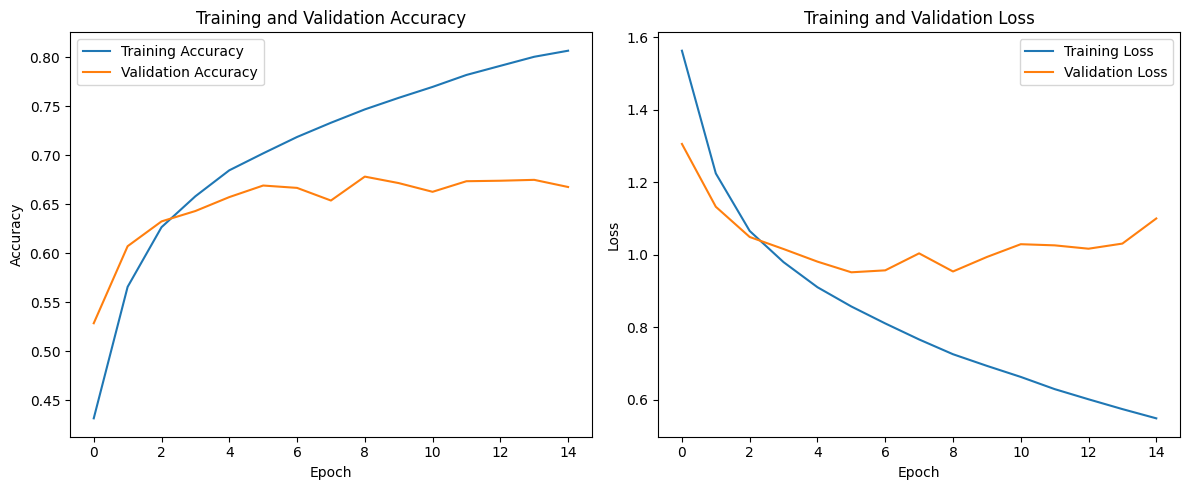

In [19]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [20]:
print("Final Training Accuracy:",
      history.history["accuracy"][-1])

print("Final Validation Accuracy:",
      history.history["val_accuracy"][-1])

Final Training Accuracy: 0.8064500093460083
Final Validation Accuracy: 0.6674000024795532


In [21]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6601 - loss: 1.1453 
Test Loss: 1.1453036069869995
Test Accuracy: 0.660099983215332


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


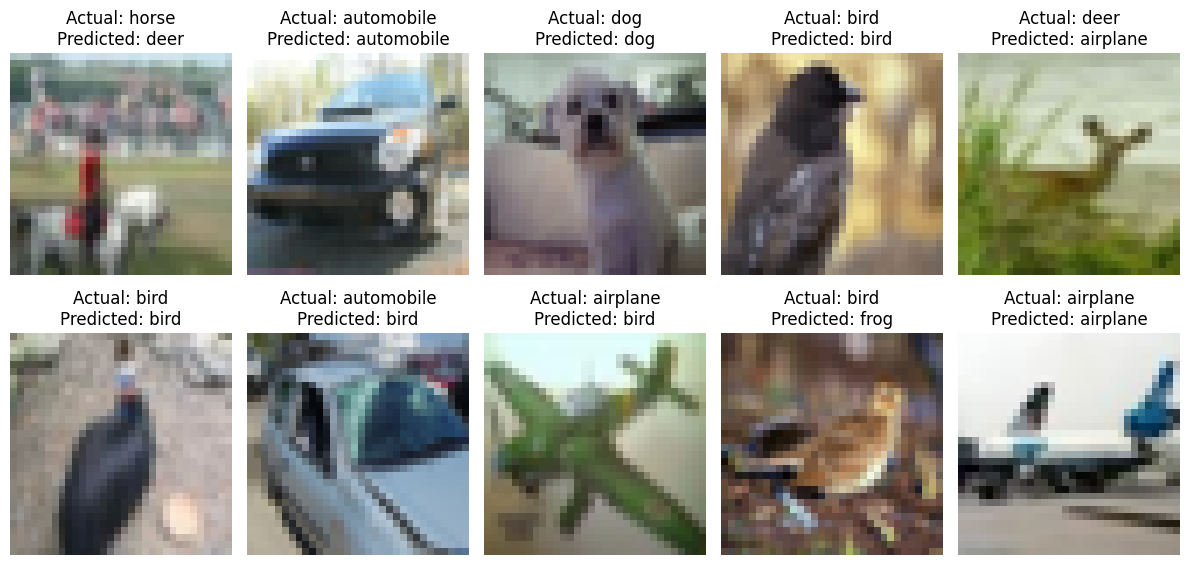

In [24]:
plt.figure(figsize=(12, 6))

for images, labels in test_data.take(1):

    predictions = model.predict(images)

    for i in range(10):
        predicted_class = np.argmax(predictions[i])

        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(
            f"Actual: {test_data.class_names[labels[i]]}\n"
            f"Predicted: {test_data.class_names[predicted_class]}"
        )

        plt.axis("off")

plt.tight_layout()
plt.show()